# Analisi dei prezzi immobiliari in Italia, 2016-2025

Questo notebook parte dalla tabella pulita del notebook 02 (quotazioni OMI, Agenzia delle Entrate) e risponde a quattro domande:

1. Come sono cambiati i prezzi di acquisto e di affitto in dieci anni?
2. Ci sono differenze tra Nord, Centro e Sud e Isole?
3. In quali semestri gli aumenti sono stati più forti?
4. In quali aree e in quale segmento (abitazioni, negozi, uffici) il rendimento lordo è più alto?

- **Input:** `data/processed/omi_semestri_puliti.csv` (si genera con il notebook 02)
- **Output:** `data/processed/aggregato_per_powerbi.csv` (poche centinaia di righe, usato dalla dashboard) e i grafici in `docs/grafici/`

I risultati scritti nelle sezioni 4-8 sono calcolati dal codice, non digitati a mano: se i dati cambiano, cambiano anche loro. Eseguire con `Kernel > Restart Kernel and Run All Cells`.

## Configurazione

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

CARTELLA_DATI = Path("..") / "data" / "processed"
CARTELLA_GRAFICI = Path("..") / "docs" / "grafici"
CARTELLA_GRAFICI.mkdir(parents=True, exist_ok=True)

AREE = ["Nord", "Centro", "Sud e Isole"]
SEGMENTI = ["Abitazioni", "Negozi", "Uffici"]
COLORI = {"Nord": "#0072B2", "Centro": "#E69F00", "Sud e Isole": "#009E73",
          "Abitazioni": "#0072B2", "Negozi": "#D55E00", "Uffici": "#CC79A7"}

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100})

def salva(fig, nome):
    for ax in fig.axes:
        ax.xaxis.set_major_locator(mdates.YearLocator(2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    fig.savefig(CARTELLA_GRAFICI / nome, dpi=130, bbox_inches="tight")
    plt.show()

# Fase 1 · Caricamento

La rilettura usa le stesse opzioni del notebook 02. Senza `keep_default_na=False`, la sigla «NA» di Napoli verrebbe letta come dato mancante.

In [2]:
omi = pd.read_csv(CARTELLA_DATI / "omi_semestri_puliti.csv",
                  keep_default_na=False, na_values=[""],
                  dtype={"Comune_ISTAT": str}, parse_dates=["Data"])
omi.shape

(1609968, 25)

Controlli prima di partire: semestri, aree e segmenti devono essere quelli attesi.

In [3]:
print("Semestri:", omi["Semestre"].nunique(), "dal", omi["Semestre"].min(), "al", omi["Semestre"].max())
print("Aree:", sorted(omi["Ripartizione"].unique()))
print("Segmenti:", sorted(omi["Segmento"].unique()))

assert omi["Semestre"].nunique() == 20
assert sorted(omi["Ripartizione"].unique()) == sorted(AREE)
assert sorted(omi["Segmento"].unique()) == sorted(SEGMENTI)
assert not omi.duplicated(["Semestre", "LinkZona", "Cod_Tip"]).any(),     "Righe duplicate: il CSV non viene dalla versione finale del notebook 02, rigeneralo"

Semestri: 20 dal 2016-H1 al 2025-H2
Aree: ['Centro', 'Nord', 'Sud e Isole']
Segmenti: ['Abitazioni', 'Negozi', 'Uffici']


# Fase 2 · Un prezzo per riga

Ogni riga ha un intervallo (minimo e massimo).

**Scelta 1.** Come prezzo di riferimento si usa il **punto medio dell'intervallo**. Se manca uno dei due estremi, il punto medio è mancante e la riga non entra nei calcoli di quel prezzo.

In [4]:
omi["Compr_medio"] = (omi["Compr_min"] + omi["Compr_max"]) / 2
omi["Loc_medio"] = (omi["Loc_min"] + omi["Loc_max"]) / 2

omi.groupby("Segmento")[["Compr_medio", "Loc_medio"]].median().round(2)

,Compr_medio,Loc_medio
Segmento,,
Abitazioni,930.0,3.40
Negozi,1000.0,5.35
Uffici,1000.0,4.40


# Fase 3 · Una tabella per semestre, area e segmento

**Scelta 2.** Per riassumere le zone di un'area si usa la **mediana**, affiancata dalla media. Pochi valori molto alti (Portofino, negozi di Milano) spostano la media ma non la mediana. È la mediana delle *zone OMI*: ogni zona pesa uguale, indipendentemente da quante abitazioni o compravendite contiene.

In [5]:
tab = (omi.groupby(["Data", "Semestre", "Anno", "Ripartizione", "Segmento"])
          .agg(Righe=("LinkZona", "size"),
               Acquisto_mediano=("Compr_medio", "median"),
               Acquisto_medio=("Compr_medio", "mean"),
               Affitto_mediano=("Loc_medio", "median"),
               Affitto_medio=("Loc_medio", "mean"))
          .reset_index()
          .sort_values(["Ripartizione", "Segmento", "Data"])
          .reset_index(drop=True))

print(tab.shape)
assert tab.shape[0] == 20 * len(AREE) * len(SEGMENTI)
assert not tab.duplicated(["Semestre", "Ripartizione", "Segmento"]).any()
tab.head()

(180, 10)


,Data,Semestre,Anno,Ripartizione,Segmento,Righe,Acquisto_mediano,Acquisto_medio,Affitto_mediano,Affitto_medio
0,2016-01-01,2016-H1,2016,Centro,Abitazioni,8718,1200.0,1437.839814,4.20,5.037082
1,2016-07-01,2016-H2,2016,Centro,Abitazioni,8786,1250.0,1466.517646,4.35,5.206295
2,2017-01-01,2017-H1,2017,Centro,Abitazioni,8769,1200.0,1429.753483,4.25,5.073064
3,2017-07-01,2017-H2,2017,Centro,Abitazioni,8792,1175.0,1400.990943,4.20,4.989279
4,2018-01-01,2018-H1,2018,Centro,Abitazioni,8767,1175.0,1381.724045,4.15,4.939980


# Fase 4 · Andamento dei prezzi

Per leggere i grafici si guardano le abitazioni, il segmento più grande. Negozi e uffici sono nella Fase 7.

## 4.1 Livelli

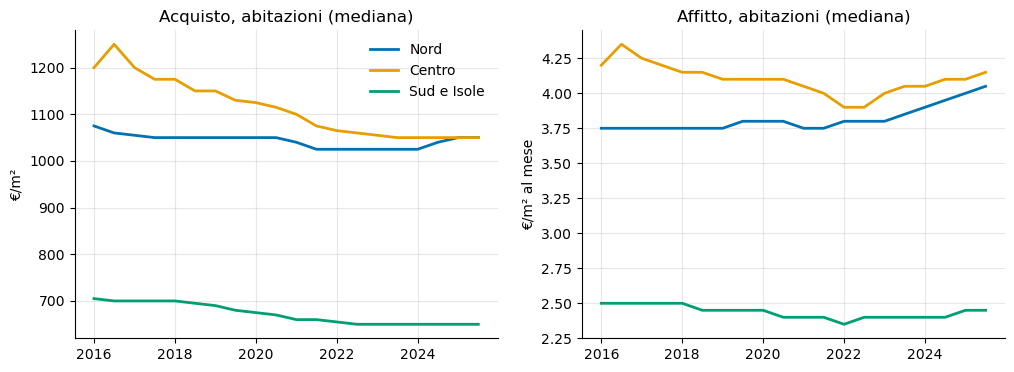

In [6]:
abit = tab[tab["Segmento"] == "Abitazioni"]

def linee_per_area(ax, dati, colonna, titolo, unita):
    for area in AREE:
        s = dati[dati["Ripartizione"] == area]
        ax.plot(s["Data"], s[colonna], label=area, color=COLORI[area], linewidth=2)
    ax.set_title(titolo)
    ax.set_ylabel(unita)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
linee_per_area(ax1, abit, "Acquisto_mediano", "Acquisto, abitazioni (mediana)", "€/m²")
linee_per_area(ax2, abit, "Affitto_mediano", "Affitto, abitazioni (mediana)", "€/m² al mese")
ax1.legend(frameon=False)
salva(fig, "01_livelli_abitazioni.png")

## 4.2 Variazione rispetto al 2016

I livelli di aree diverse non si confrontano a occhio. Si porta quindi ogni serie a **100 nel primo semestre** (2016-H1): un valore di 110 vuol dire +10% rispetto a quel semestre.

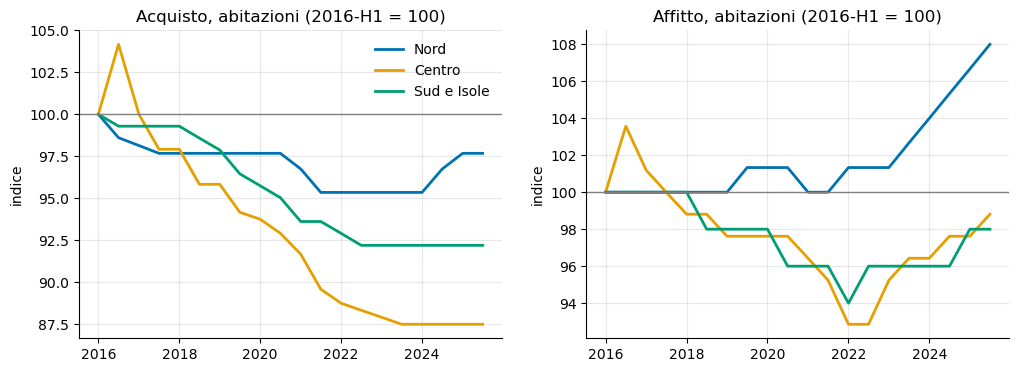

In [7]:
tab["Indice_acquisto"] = tab["Acquisto_mediano"] / tab.groupby(["Ripartizione", "Segmento"])["Acquisto_mediano"].transform("first") * 100
tab["Indice_affitto"] = tab["Affitto_mediano"] / tab.groupby(["Ripartizione", "Segmento"])["Affitto_mediano"].transform("first") * 100

abit = tab[tab["Segmento"] == "Abitazioni"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
linee_per_area(ax1, abit, "Indice_acquisto", "Acquisto, abitazioni (2016-H1 = 100)", "indice")
linee_per_area(ax2, abit, "Indice_affitto", "Affitto, abitazioni (2016-H1 = 100)", "indice")
for ax in (ax1, ax2):
    ax.axhline(100, color="grey", linewidth=1)
ax1.legend(frameon=False)
salva(fig, "02_indice_abitazioni.png")

## 4.3 Variazione complessiva

Variazione % tra il primo e l'ultimo semestre, per area e segmento.

In [8]:
primo, ultimo = tab["Data"].min(), tab["Data"].max()
sem_primo = tab.loc[tab["Data"] == primo, "Semestre"].iloc[0]
sem_ultimo = tab.loc[tab["Data"] == ultimo, "Semestre"].iloc[0]

def variazione_totale(colonna_indice):
    ultimi = tab[tab["Data"] == ultimo]
    t = ultimi.pivot_table(index="Ripartizione", columns="Segmento", values=colonna_indice)
    return (t.loc[AREE, SEGMENTI] - 100).round(1)

var_tot_acquisto = variazione_totale("Indice_acquisto")
var_tot_affitto = variazione_totale("Indice_affitto")

print(f"Acquisto: variazione % {sem_primo} -> {sem_ultimo}")
display(var_tot_acquisto)
print(f"Affitto: variazione % {sem_primo} -> {sem_ultimo}")
display(var_tot_affitto)

Acquisto: variazione % 2016-H1 -> 2025-H2


Segmento,Abitazioni,Negozi,Uffici
Ripartizione,,,
Nord,-2.3,-6.7,-1.3
Centro,-12.5,-20.8,-15.0
Sud e Isole,-7.8,-12.9,-10.0


Affitto: variazione % 2016-H1 -> 2025-H2


Segmento,Abitazioni,Negozi,Uffici
Ripartizione,,,
Nord,8.0,-0.9,6.5
Centro,-1.2,-13.6,-14.3
Sud e Isole,-2.0,-4.4,-4.2


## 4.4 Controllo: stesse zone nei due semestri

La mediana di un'area può cambiare perché cambiano i prezzi, ma anche perché cambia l'elenco delle zone (fusioni di comuni, zone eliminate o accorpate). Per escluderlo si ripete il calcolo solo sulle **coppie zona + tipologia presenti in entrambi i semestri**: per ognuna si calcola la variazione % e poi si prende la mediana per area e segmento.

In [9]:
def variazione_stesse_zone(colonna):
    base = omi.loc[omi["Data"] == primo, ["LinkZona", "Cod_Tip", "Ripartizione", "Segmento", colonna]]
    fine = omi.loc[omi["Data"] == ultimo, ["LinkZona", "Cod_Tip", colonna]]
    coppie = base.merge(fine, on=["LinkZona", "Cod_Tip"], suffixes=("_primo", "_ultimo"))
    coppie = coppie.dropna(subset=[colonna + "_primo", colonna + "_ultimo"])
    coppie["Var_pct"] = (coppie[colonna + "_ultimo"] / coppie[colonna + "_primo"] - 1) * 100
    tabella = (coppie.groupby(["Ripartizione", "Segmento"])["Var_pct"].median()
                     .unstack().loc[AREE, SEGMENTI].round(1))
    quota_invariate = (coppie["Var_pct"] == 0).mean()
    return tabella, len(coppie), quota_invariate

for nome, colonna in [("Acquisto", "Compr_medio"), ("Affitto", "Loc_medio")]:
    tabella, n_coppie, invariate = variazione_stesse_zone(colonna)
    print(f"{nome}, stesse zone: {n_coppie} coppie zona + tipologia, {invariate:.0%} con prezzo invariato")
    display(tabella)

Acquisto, stesse zone: 71208 coppie zona + tipologia, 17% con prezzo invariato


Segmento,Abitazioni,Negozi,Uffici
Ripartizione,,,
Nord,0.0,-5.3,0.0
Centro,-10.3,-22.4,-16.7
Sud e Isole,-5.4,-6.9,-5.6


Affitto, stesse zone: 64857 coppie zona + tipologia, 22% con prezzo invariato


Segmento,Abitazioni,Negozi,Uffici
Ripartizione,,,
Nord,1.7,0.0,0.0
Centro,-1.3,-14.0,-13.2
Sud e Isole,0.0,-2.0,-2.9


Se questa tabella è vicina alla 4.3, la variazione non dipende dal cambio delle zone. La quota di prezzi invariati mostra quanto le quotazioni OMI cambino «a gradini»: una quota alta significa che molte zone non sono state riviste in dieci anni.

# Fase 5 · Dove e quando i prezzi sono saliti di più

**Scelta 3.** La variazione si calcola **sull'anno**: ogni semestre si confronta con lo stesso semestre dell'anno precedente (due semestri prima). È meno rumorosa del confronto semestre su semestre, perché le quotazioni OMI cambiano a gradini.

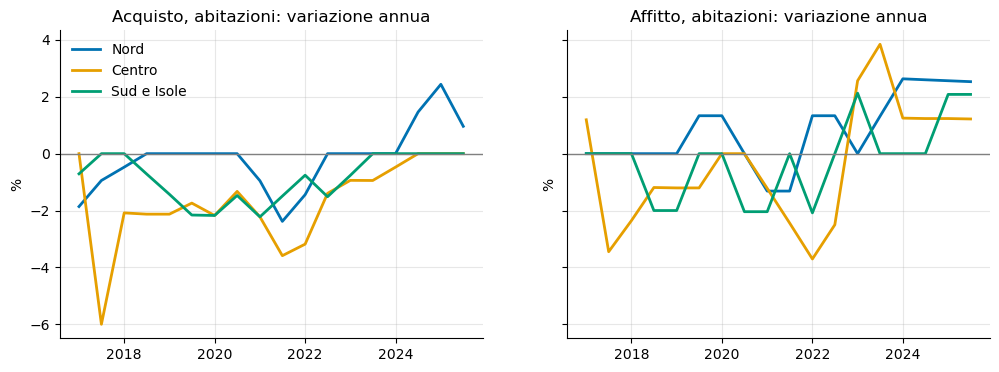

In [10]:
gruppi = tab.groupby(["Ripartizione", "Segmento"])
tab["Var_annua_acquisto_pct"] = (tab["Acquisto_mediano"] / gruppi["Acquisto_mediano"].shift(2) - 1) * 100
tab["Var_annua_affitto_pct"] = (tab["Affitto_mediano"] / gruppi["Affitto_mediano"].shift(2) - 1) * 100

abit = tab[tab["Segmento"] == "Abitazioni"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
linee_per_area(ax1, abit, "Var_annua_acquisto_pct", "Acquisto, abitazioni: variazione annua", "%")
linee_per_area(ax2, abit, "Var_annua_affitto_pct", "Affitto, abitazioni: variazione annua", "%")
for ax in (ax1, ax2):
    ax.axhline(0, color="grey", linewidth=1)
ax1.legend(frameon=False)
salva(fig, "03_variazione_annua_abitazioni.png")

I tre semestri con la variazione annua più alta, per area (abitazioni):

In [11]:
def semestri_top(colonna, quanti=3):
    t = abit.dropna(subset=[colonna])
    t = t.sort_values(colonna, ascending=False).groupby("Ripartizione").head(quanti)
    t = t.sort_values(["Ripartizione", colonna], ascending=[True, False])
    return t[["Ripartizione", "Semestre", colonna]].round(1).reset_index(drop=True)

print("Acquisto")
display(semestri_top("Var_annua_acquisto_pct"))
print("Affitto")
display(semestri_top("Var_annua_affitto_pct"))

Acquisto


,Ripartizione,Semestre,Var_annua_acquisto_pct
0,Centro,2017-H1,0.0
1,Centro,2025-H2,0.0
2,Centro,2025-H1,0.0
3,Nord,2025-H1,2.4
4,Nord,2024-H2,1.5
5,Nord,2025-H2,1.0
6,Sud e Isole,2017-H2,0.0
7,Sud e Isole,2018-H1,0.0
8,Sud e Isole,2023-H2,0.0


Affitto


,Ripartizione,Semestre,Var_annua_affitto_pct
0,Centro,2023-H2,3.8
1,Centro,2023-H1,2.6
2,Centro,2024-H1,1.2
3,Nord,2024-H1,2.6
4,Nord,2024-H2,2.6
5,Nord,2025-H1,2.6
6,Sud e Isole,2023-H1,2.1
7,Sud e Isole,2025-H2,2.1
8,Sud e Isole,2025-H1,2.1


# Fase 6 · Acquisto e affitto a confronto

Se i prezzi di acquisto salgono più degli affitti, il rendimento di chi compra per affittare scende, e viceversa. Si confrontano i due indici (2016-H1 = 100) per le abitazioni.

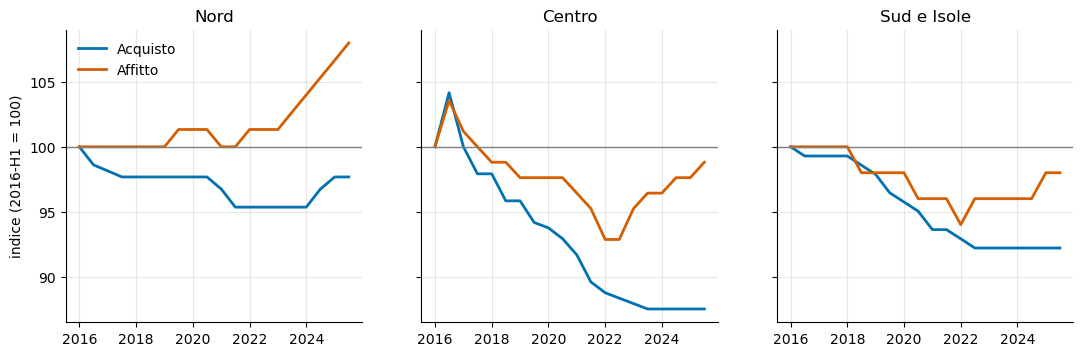

In [12]:
fig, assi = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, area in zip(assi, AREE):
    s = abit[abit["Ripartizione"] == area]
    ax.plot(s["Data"], s["Indice_acquisto"], label="Acquisto", color="#0072B2", linewidth=2)
    ax.plot(s["Data"], s["Indice_affitto"], label="Affitto", color="#D55E00", linewidth=2)
    ax.axhline(100, color="grey", linewidth=1)
    ax.set_title(area)
assi[0].set_ylabel("indice (2016-H1 = 100)")
assi[0].legend(frameon=False)
salva(fig, "04_acquisto_contro_affitto.png")

# Fase 7 · Abitazioni, negozi, uffici

Qui si guarda l'Italia intera: la mediana di tutte le zone, per segmento.

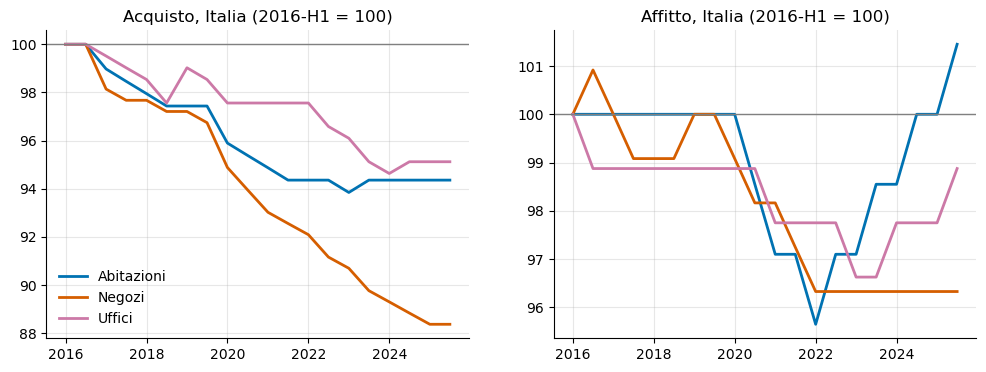

In [13]:
italia = (omi.groupby(["Data", "Semestre", "Segmento"])
             .agg(Acquisto_mediano=("Compr_medio", "median"),
                  Affitto_mediano=("Loc_medio", "median"))
             .reset_index()
             .sort_values(["Segmento", "Data"]))

italia["Indice_acquisto"] = italia["Acquisto_mediano"] / italia.groupby("Segmento")["Acquisto_mediano"].transform("first") * 100
italia["Indice_affitto"] = italia["Affitto_mediano"] / italia.groupby("Segmento")["Affitto_mediano"].transform("first") * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for segmento in SEGMENTI:
    s = italia[italia["Segmento"] == segmento]
    ax1.plot(s["Data"], s["Indice_acquisto"], label=segmento, color=COLORI[segmento], linewidth=2)
    ax2.plot(s["Data"], s["Indice_affitto"], label=segmento, color=COLORI[segmento], linewidth=2)
ax1.set_title("Acquisto, Italia (2016-H1 = 100)")
ax2.set_title("Affitto, Italia (2016-H1 = 100)")
for ax in (ax1, ax2):
    ax.axhline(100, color="grey", linewidth=1)
ax1.legend(frameon=False)
salva(fig, "05_segmenti_italia.png")

# Fase 8 · Rendimento lordo

Il **rendimento lordo** è l'affitto di un anno diviso il prezzo di acquisto: se un immobile costa 1.000 €/m² e si affitta a 4 €/m² al mese, rende 4 × 12 / 1.000 = 4,8% l'anno.

**Scelta 4.** Per avere prezzo e affitto sulla stessa base si usano solo le righe con superficie **lorda** nell'affitto (`Sup_NL_loc` = L; il prezzo di acquisto è sempre su superficie lorda) e con entrambi i prezzi presenti.

È un rendimento *lordo*: non toglie tasse, spese, periodi senza inquilino. Serve a confrontare aree e segmenti, non a prevedere un guadagno.

In [14]:
omi["Rendimento_lordo_pct"] = omi["Loc_medio"] * 12 / omi["Compr_medio"] * 100

usabili = (omi["Sup_NL_loc"] == "L") & omi["Rendimento_lordo_pct"].notna()
print(f"Righe usate per il rendimento: {usabili.sum()} su {len(omi)} ({usabili.mean():.0%})")

omi_rend = omi[usabili]
omi_rend["Rendimento_lordo_pct"].describe().round(2)

Righe usate per il rendimento: 1154385 su 1609968 (72%)


count    1154385.00
mean           4.79
std            1.30
min            1.17
25%            3.92
50%            4.57
75%            5.41
max           20.66
Name: Rendimento_lordo_pct, dtype: float64

Il rendimento riga per riga può avere valori estremi dove prezzo o affitto sono poco affidabili. Per questo ogni area e segmento è riassunto con la mediana.

In [15]:
rend = (omi_rend.groupby(["Data", "Ripartizione", "Segmento"])
                .agg(Rendimento_lordo_pct=("Rendimento_lordo_pct", "median"),
                     Righe_rendimento=("LinkZona", "size"))
                .reset_index())

tab = tab.merge(rend, on=["Data", "Ripartizione", "Segmento"], how="left")
tab.shape

(180, 16)

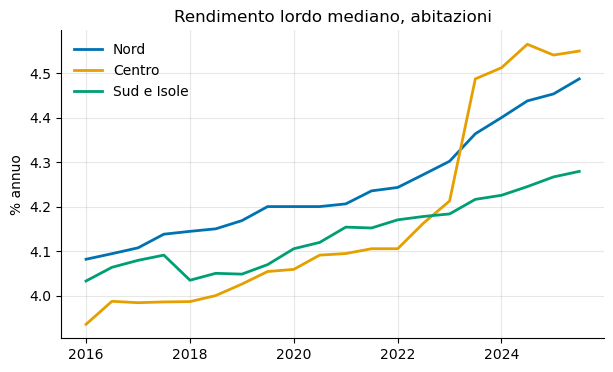

In [16]:
abit = tab[tab["Segmento"] == "Abitazioni"]
fig, ax = plt.subplots(figsize=(7, 4))
linee_per_area(ax, abit, "Rendimento_lordo_pct", "Rendimento lordo mediano, abitazioni", "% annuo")
ax.legend(frameon=False)
salva(fig, "06_rendimento_abitazioni.png")

Rendimento lordo mediano nell'ultimo semestre e medio sui 20 semestri, per area e segmento (%):

In [17]:
ultimo_sem = tab[tab["Data"] == ultimo].pivot_table(index="Ripartizione", columns="Segmento",
                                                    values="Rendimento_lordo_pct").loc[AREE, SEGMENTI].round(2)
tutti_sem = tab.pivot_table(index="Ripartizione", columns="Segmento",
                            values="Rendimento_lordo_pct").loc[AREE, SEGMENTI].round(2)

print(f"Ultimo semestre ({sem_ultimo})")
display(ultimo_sem)
print("Media sui 20 semestri")
display(tutti_sem)

Ultimo semestre (2025-H2)


Segmento,Abitazioni,Negozi,Uffici
Ripartizione,,,
Nord,4.49,6.53,5.31
Centro,4.55,6.33,5.51
Sud e Isole,4.28,6.05,5.54


Media sui 20 semestri


Segmento,Abitazioni,Negozi,Uffici
Ripartizione,,,
Nord,4.24,6.18,5.16
Centro,4.17,6.09,5.10
Sud e Isole,4.14,5.86,5.29


# Fase 9 · Sintesi dei risultati

Le frasi seguenti sono generate dai numeri delle fasi precedenti.

In [18]:
def elenco(serie):
    return ", ".join(f"{area} {valore:+.1f}%" for area, valore in serie.items())

print(f"Variazione {sem_primo} -> {sem_ultimo}, abitazioni (mediana delle zone):")
print("  Acquisto:", elenco(var_tot_acquisto["Abitazioni"]))
print("  Affitto: ", elenco(var_tot_affitto["Abitazioni"]))

for nome, colonna in [("acquisto", "Var_annua_acquisto_pct"), ("affitto", "Var_annua_affitto_pct")]:
    riga = abit.loc[abit[colonna].idxmax()]
    print(f"Aumento annuo più forte, {nome} abitazioni: {riga['Ripartizione']}, {riga['Semestre']} ({riga[colonna]:+.1f}%)")

crescita = italia[italia["Data"] == ultimo].set_index("Segmento")["Indice_acquisto"] - 100
print("Acquisto in Italia per segmento:", ", ".join(f"{s} {crescita[s]:+.1f}%" for s in SEGMENTI))

migliore = ultimo_sem.stack().idxmax()
peggiore = ultimo_sem.stack().idxmin()
print(f"Rendimento lordo mediano più alto nel {sem_ultimo}: {migliore[0]}, {migliore[1]} ({ultimo_sem.stack().max():.2f}%)")
print(f"Rendimento lordo mediano più basso nel {sem_ultimo}: {peggiore[0]}, {peggiore[1]} ({ultimo_sem.stack().min():.2f}%)")

Variazione 2016-H1 -> 2025-H2, abitazioni (mediana delle zone):
  Acquisto: Nord -2.3%, Centro -12.5%, Sud e Isole -7.8%
  Affitto:  Nord +8.0%, Centro -1.2%, Sud e Isole -2.0%
Aumento annuo più forte, acquisto abitazioni: Nord, 2025-H1 (+2.4%)
Aumento annuo più forte, affitto abitazioni: Centro, 2023-H2 (+3.8%)
Acquisto in Italia per segmento: Abitazioni -5.6%, Negozi -11.6%, Uffici -4.9%
Rendimento lordo mediano più alto nel 2025-H2: Nord, Negozi (6.53%)
Rendimento lordo mediano più basso nel 2025-H2: Sud e Isole, Abitazioni (4.28%)


# Fase 10 · Tabella per la dashboard

Una riga per semestre, area e segmento, con tutto quello che serve a Power BI. Il file è piccolo e va su GitHub.

Formato: separatore `;` e virgola decimale, che Power BI su un computer con impostazioni italiane legge senza correzioni.

In [19]:
colonne = ["Data", "Semestre", "Anno", "Ripartizione", "Segmento", "Righe",
           "Acquisto_mediano", "Acquisto_medio", "Affitto_mediano", "Affitto_medio",
           "Indice_acquisto", "Indice_affitto",
           "Var_annua_acquisto_pct", "Var_annua_affitto_pct",
           "Rendimento_lordo_pct", "Righe_rendimento"]

per_powerbi = tab[colonne].copy()
numeriche = per_powerbi.select_dtypes("number").columns
per_powerbi[numeriche] = per_powerbi[numeriche].round(2)
percorso_out = CARTELLA_DATI / "aggregato_per_powerbi.csv"
per_powerbi.to_csv(percorso_out, index=False, sep=";", decimal=",")

print(per_powerbi.shape, f"{percorso_out.stat().st_size / 1024:.0f} KB")

(180, 16) 18 KB


Controllo del file salvato: si rilegge e si confronta con la tabella in memoria.

In [20]:
riletto = pd.read_csv(percorso_out, sep=";", decimal=",", parse_dates=["Data"])
print(riletto.shape, per_powerbi.shape)
assert riletto.shape == per_powerbi.shape
assert riletto["Acquisto_mediano"].sum().round(1) == per_powerbi["Acquisto_mediano"].sum().round(1)
riletto.head()

(180, 16) (180, 16)


,Data,Semestre,Anno,Ripartizione,Segmento,Righe,Acquisto_mediano,Acquisto_medio,Affitto_mediano,Affitto_medio,Indice_acquisto,Indice_affitto,Var_annua_acquisto_pct,Var_annua_affitto_pct,Rendimento_lordo_pct,Righe_rendimento
0,2016-01-01,2016-H1,2016,Centro,Abitazioni,8718,1200.0,1437.84,4.20,5.04,100.00,100.00,NaN,NaN,3.94,4571
1,2016-07-01,2016-H2,2016,Centro,Abitazioni,8786,1250.0,1466.52,4.35,5.21,104.17,103.57,NaN,NaN,3.99,3933
2,2017-01-01,2017-H1,2017,Centro,Abitazioni,8769,1200.0,1429.75,4.25,5.07,100.00,101.19,0.00,1.19,3.98,4151
3,2017-07-01,2017-H2,2017,Centro,Abitazioni,8792,1175.0,1400.99,4.20,4.99,97.92,100.00,-6.00,-3.45,3.99,4280
4,2018-01-01,2018-H1,2018,Centro,Abitazioni,8767,1175.0,1381.72,4.15,4.94,97.92,98.81,-2.08,-2.35,3.99,4262


# Limiti dell'analisi

- **Stime, non prezzi di vendita.** L'OMI pubblica intervalli «di larga massima». Le quotazioni cambiano a gradini, quindi i movimenti piccoli o di breve durata vanno letti con cautela.
- **Mediana delle zone.** Ogni zona OMI pesa uguale, grande o piccola che sia. Non è il prezzo medio pagato in un'area.
- **Tre aree.** Nord, Centro e Sud e Isole nascondono grandi differenze tra regioni e tra città e campagna.
- **Zone che cambiano.** Fusioni di comuni e il calo di zone del 2024-H2 (vedi notebook 02) possono spostare le mediane senza che i prezzi cambino.
- **Rendimento lordo.** Non considera tasse, spese, sfitto. Dipende da affitto e prezzo stimati dall'OMI, e usa solo le righe con affitto su superficie lorda.
- **Prezzi nominali.** Non sono corretti per l'inflazione.
- **Solo OMI.** Questo notebook non usa l'indice dei prezzi Istat.

**Fonte:** «Agenzia delle Entrate – OMI», licenza CC-BY 4.0.